# Nifty Commodities benchmark return prediction

**Team 12 · Project ID 12 · Machine Learning with Business Data (UE24AM342AA4)**

| Member | SRN |
|---|---|
| Darshan Govekar | PES1UG24AM355 |
| Dhanraj Rathod | PES1UG24AM359 |
| Shridhar Umesh Golipalle | PES1UG25AM814 |

This executed notebook examines the actual saved dataset, trained-model metadata,
predictions and measurements. It performs no model fitting and makes no network
requests. The experiment predicts a continuous **next observed session return**
using information available after the previous session's close. All reported
numbers below are loaded or independently calculated from the saved artifacts.


In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'results' / 'metrics.csv').exists() and (ROOT.parent / 'results' / 'metrics.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'pipeline.py').exists(), 'Run this notebook from the project folder or notebooks folder.'
sys.path.insert(0, str(ROOT))
from src.pipeline import FEATURE_COLUMNS, build_features, split_dataset

def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding='utf-8'))

pd.set_option('display.max_columns', 16)
pd.set_option('display.max_colwidth', 95)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
provenance = read_json('data/raw/provenance.json')
summary = read_json('results/run_summary.json')
data_summary = read_json('results/data_summary.json')
scores = pd.read_csv(ROOT / 'results/metrics.csv')
raw_all = pd.read_csv(ROOT / 'data/raw/nifty_commodities_daily.csv')
raw = pd.read_csv(ROOT / 'data/raw/nifty_commodities_complete_ohlc.csv').rename(columns=str.title)
raw['Date'] = pd.to_datetime(raw['Date'])
parts = {name: pd.read_csv(ROOT / f'data/processed/{name}.csv', parse_dates=['Date', 'TargetDate'])
         for name in ['train', 'validation', 'test']}
predictions = {name: pd.read_csv(ROOT / f'results/{name}_predictions.csv', parse_dates=['Date', 'TargetDate'])
               for name in ['validation', 'test']}
display(Markdown('Artifacts loaded. This notebook reads the saved experiment without retraining.'))


Artifacts loaded. This notebook reads the saved experiment without retraining.

## 1. Source, provenance and data quality

The provider is NSE Indices Limited. Nifty Commodities is the assigned equity
benchmark; the values below are **price index points**, not spot commodity
prices. Price returns exclude reinvested dividends. The requested data freeze
and the actual final available session can differ. Weekends, holidays and
unreturned sessions are not fabricated.

The full official response is retained. The experiment uses the complete-OHLC
subset because the initial history lacks Open/High/Low. The excluded era and
its size are shown explicitly, and genuine market shocks remain in the data.


In [2]:
source_overview = {
    'Provider': provenance['provider'],
    'Series': provenance['dataset'],
    'Requested start': provenance['requested_start'],
    'Requested freeze': provenance['requested_end'],
    'Actual full-source start': provenance['actual_start'],
    'Actual full-source end': provenance['actual_end'],
    'Full-source rows': len(raw_all),
    'Complete-OHLC rows': len(raw),
    'Complete-OHLC first session': raw['Date'].min().date().isoformat(),
    'Complete-OHLC last session': raw['Date'].max().date().isoformat(),
    'Excluded rows lacking OHLC': len(raw_all) - len(raw),
    'Identical duplicate dates removed at download': provenance['identical_duplicates_removed'],
}
display(pd.Series(source_overview, name='Saved source evidence').to_frame())
display(raw_all.isna().sum().rename('Full-source missing cells').to_frame())
assert raw['Date'].is_unique and raw['Date'].is_monotonic_increasing
assert np.isfinite(raw[['Open', 'High', 'Low', 'Close']]).all().all()
assert (raw[['Open', 'High', 'Low', 'Close']] > 0).all().all()
assert hashlib.sha256((ROOT / 'data/raw/nifty_commodities_complete_ohlc.csv').read_bytes()).hexdigest() == provenance['complete_ohlc_sha256']
request_hashes_verified = 0
for request in provenance['requests']:
    response_path = ROOT / 'data/raw' / request['response_file']
    assert hashlib.sha256(response_path.read_bytes()).hexdigest() == request['response_sha256']
    request_hashes_verified += 1
display(Markdown(f'CSV checksum and **{request_hashes_verified}** downloaded-response checksums verified.'))
display(Markdown(f"[Official index]({provenance['index_page']}) · [Historical data]({provenance['historical_data_page']})"))
display(raw.head())


,Saved source evidence
Provider,NSE Indices Limited
Series,Nifty Commodities daily price index OHLC
Requested start,2010-01-01
Requested freeze,2026-11-10
Actual full-source start,2010-01-04
Actual full-source end,2026-11-09
Full-source rows,4182
Complete-OHLC rows,3644
Complete-OHLC first session,2012-02-27
Complete-OHLC last session,2026-11-09


,Full-source missing cells
date,0
open,538
high,538
low,538
close,0


CSV checksum and **17** downloaded-response checksums verified.

[Official index](https://www.niftyindices.com/indices/equity/thematic-indices/nifty-commodities) · [Historical data](https://www.niftyindices.com/reports/historical-data)

,Date,Open,High,Low,Close
0,2012-02-27,2614.350000,2614.350000,2507.300000,2517.750000
1,2012-02-28,2528.650000,2580.600000,2528.650000,2574.200000
2,2012-02-29,2603.000000,2631.100000,2581.050000,2613.400000
3,2012-03-01,2606.800000,2611.250000,2576.250000,2599.250000
4,2012-03-02,2612.400000,2621.950000,2587.600000,2596.550000


## 2. Target, causal features and chronological partitions

At the close of feature date `t`, the target is
`100 × (Close[next observed session] / Close[t] − 1)`.
It is measured in **percentage points**: 1.0 means a 1% return. `TargetDate`
keeps the realization date attached to each prediction. The 23 input columns
exclude both `target_return` and `TargetDate`.

All rolling windows end at the feature date. The initial rolling-window warm-up
and the final unobserved target are excluded. Chronological boundaries use
feature dates through 2021, 2022–2023, and 2024 onward. A boundary row is purged
when its outcome date reaches the next partition's first feature date.

The official sample includes special Saturday and Sunday sessions. Weekday
features use a **seven-day** cycle, so every calendar day stays distinct.
The source sessions remain in the data; we never invent missing calendar days.


In [3]:
feature_groups = [
    ('Current and lagged returns', 'return_1; return_lag_1/2/3/5', '100 × close-to-close percentage change, with stated backward lags'),
    ('Momentum', 'momentum_5/10/20', '100 × (Close[t]/Close[t-window] - 1)'),
    ('Volatility', 'volatility_5/20', 'Trailing sample standard deviation of daily percentage returns'),
    ('Mean return', 'mean_return_5/20', 'Trailing mean of daily percentage returns'),
    ('Moving-average distance', 'close_to_sma_5/20', '100 × (Close[t]/trailing mean Close - 1)'),
    ('Intraday and range', 'intraday_return; range_pct; overnight_gap', 'Close/Open return; (High-Low)/Close; Open/previous Close gap'),
    ('Oscillator', 'rsi_14', 'RSI from trailing 14-session mean upward/downward price changes'),
    ('Drawdown', 'drawdown_60', '100 × (Close[t]/trailing 60-session maximum Close - 1)'),
    ('Calendar', 'weekday_sin/cos; month_sin/cos', 'Seven-day weekday cycle and twelve-month cycle, from feature date only'),
]
display(pd.DataFrame(feature_groups, columns=['Group', 'Columns', 'Definition']))
assert len(FEATURE_COLUMNS) == 23
assert 'target_return' not in FEATURE_COLUMNS and 'TargetDate' not in FEATURE_COLUMNS
partition_table = pd.DataFrame([
    {'partition': name, 'rows': len(part), 'feature_start': part.Date.min().date(),
     'feature_end': part.Date.max().date(), 'target_end': part.TargetDate.max().date()}
    for name, part in parts.items()
])
display(partition_table)
assert parts['train'].TargetDate.max() < parts['validation'].Date.min()
assert parts['validation'].TargetDate.max() < parts['test'].Date.min()
assert parts['test'].TargetDate.max() <= pd.Timestamp('2026-11-10')
# Independently verify targets against the official close series.
reference = raw.assign(expected_target=100*(raw.Close.shift(-1)/raw.Close-1),
                       expected_date=raw.Date.shift(-1)).set_index('Date')
for part in parts.values():
    expected = reference.loc[part.Date]
    np.testing.assert_allclose(part.target_return, expected.expected_target, rtol=1e-10, atol=1e-10)
    assert np.array_equal(part.TargetDate.to_numpy(), expected.expected_date.to_numpy())
# Appending future data must not change historical feature values.
prefix = build_features(raw.iloc[:1000].copy()).set_index('Date')
complete = build_features(raw.copy()).set_index('Date')
common = prefix.index.intersection(complete.index)
np.testing.assert_allclose(prefix.loc[common, FEATURE_COLUMNS], complete.loc[common, FEATURE_COLUMNS], rtol=1e-10, atol=1e-10)
display(Markdown('Target alignment, strict boundary separation, data freeze and causal prefix invariance verified.'))
display(parts['test'][['Date', 'TargetDate', 'Close', 'return_1', 'momentum_5', 'target_return']].head())


,Group,Columns,Definition
0,Current and lagged returns,return_1; return_lag_1/2/3/5,"100 × close-to-close percentage change, with stated backward lags"
1,Momentum,momentum_5/10/20,100 × (Close[t]/Close[t-window] - 1)
2,Volatility,volatility_5/20,Trailing sample standard deviation of daily percentage returns
3,Mean return,mean_return_5/20,Trailing mean of daily percentage returns
4,Moving-average distance,close_to_sma_5/20,100 × (Close[t]/trailing mean Close - 1)
5,Intraday and range,intraday_return; range_pct; overnight_gap,Close/Open return; (High-Low)/Close; Open/previous Close gap
6,Oscillator,rsi_14,RSI from trailing 14-session mean upward/downward price changes
7,Drawdown,drawdown_60,100 × (Close[t]/trailing 60-session maximum Close - 1)
8,Calendar,weekday_sin/cos; month_sin/cos,"Seven-day weekday cycle and twelve-month cycle, from feature date only"


,partition,rows,feature_start,feature_end,target_end
0,train,2380,2012-05-22,2021-12-30,2021-12-31
1,validation,493,2022-01-03,2023-12-28,2023-12-29
2,test,709,2024-01-01,2026-11-08,2026-11-09


Target alignment, strict boundary separation, data freeze and causal prefix invariance verified.

,Date,TargetDate,Close,return_1,momentum_5,target_return
0,2024-01-01,2024-01-02,7718.750000,0.038233,3.323762,-0.044696
1,2024-01-02,2024-01-03,7715.300000,-0.044696,1.973976,-0.482807
2,2024-01-03,2024-01-04,7678.050000,-0.482807,0.489487,0.599762
3,2024-01-04,2024-01-05,7724.100000,0.599762,-0.057579,-0.254399
4,2024-01-05,2024-01-08,7704.450000,-0.254399,-0.147101,-0.791101


## 3. Exploratory analysis of training observations

The distribution, volatility and correlation figures in this section use only
the training partition. Large genuine return observations are retained. Feature
correlation can make attribution unstable and motivates a regularized linear
baseline alongside nonlinear models.


,Training target return (%)
count,2380.000000
mean,0.047596
std,1.276944
min,-12.248414
25%,-0.602251
50%,0.089291
75%,0.771993
max,7.602366
skew,-0.671606
excess_kurtosis,7.659522


Training sessions with a positive target return: **53.28%**.

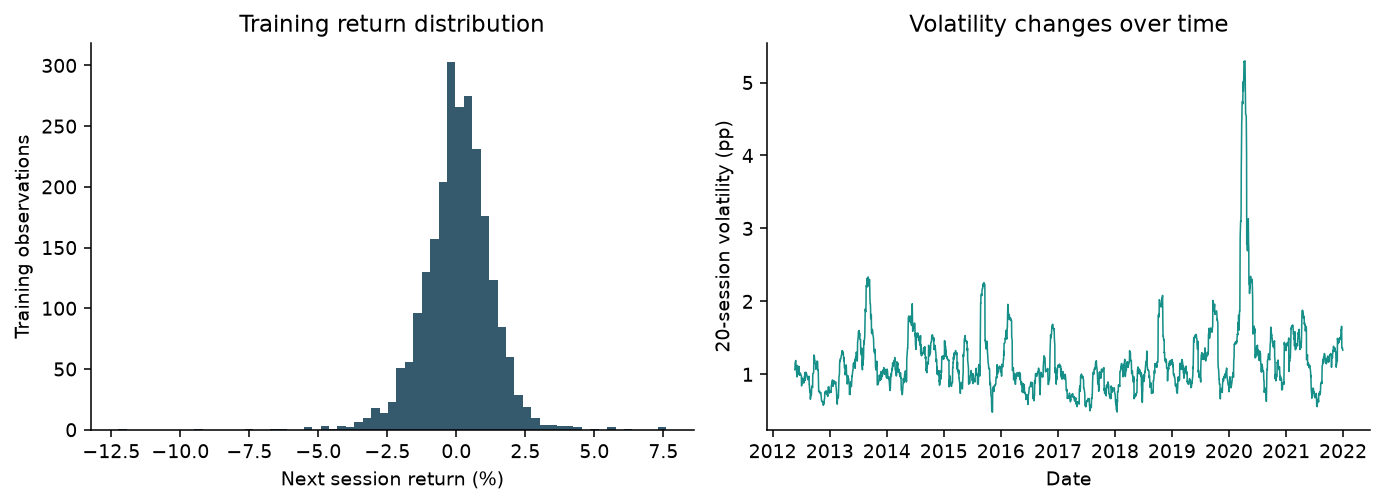

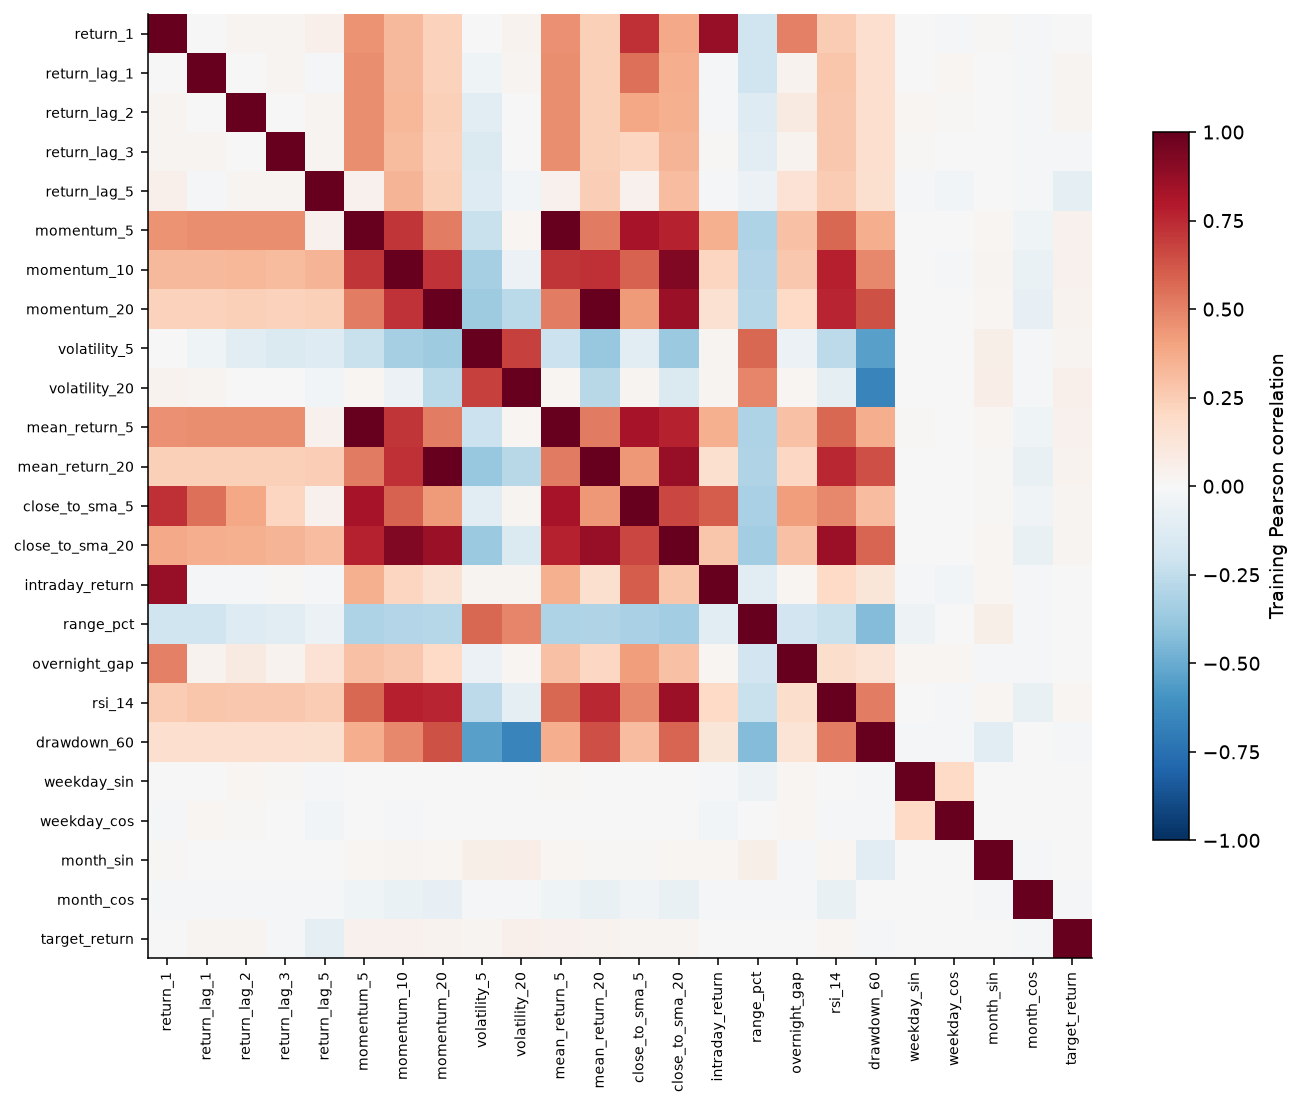

In [4]:
training = parts['train']
eda = training.target_return.describe().to_frame('Training target return (%)')
eda.loc['skew'] = training.target_return.skew()
eda.loc['excess_kurtosis'] = training.target_return.kurt()
display(eda)
display(Markdown(f'Training sessions with a positive target return: **{(training.target_return > 0).mean():.2%}**.'))
display(Image(filename=str(ROOT / 'results/figures/02_eda.png'), width=1000))
display(Image(filename=str(ROOT / 'results/figures/03_correlation.png'), width=950))


## 4. Expanding-window validation and training-only scaling

Three expanding training-period folds each reserve a 252-session outer
evaluation block. A separate final 126-session block inside the earlier
training window monitors stopping. One-row gaps and outcome-date assertions
separate those blocks. The outer evaluation labels do not select epochs.
Scalers are fitted anew on each inner training window. The following mean and
sample standard deviation summarize the actual recorded outer-fold scores.


In [5]:
cv = pd.read_csv(ROOT / 'results/cv_metrics.csv')
assert not summary['cv_skipped'], 'The final notebook requires the completed cross-validation experiment.'
display(cv[['fold', 'model', 'train_n', 'early_stopping_n', 'validation_n', 'train_end', 'validation_start', 'RMSE', 'MAE', 'R2']])
cv_summary = cv.groupby('model')[['RMSE', 'MAE', 'R2', 'direction_accuracy']].agg(['mean', 'std'])
display(cv_summary)
import joblib
scaler = joblib.load(ROOT / 'models/scaler.joblib')
np.testing.assert_allclose(scaler.mean_, training[FEATURE_COLUMNS].mean().to_numpy(), rtol=1e-10, atol=1e-10)
np.testing.assert_allclose(scaler.scale_, training[FEATURE_COLUMNS].std(ddof=0).to_numpy(), rtol=1e-10, atol=1e-10)
display(Markdown('The saved final StandardScaler mean and scale match training observations only.'))


,fold,model,train_n,early_stopping_n,validation_n,train_end,validation_start,RMSE,MAE,R2
0,1,xgboost,1496,126,252,2018-06-05,2018-12-13,1.195113,0.923527,0.000395
1,1,keras,1496,126,252,2018-06-05,2018-12-13,1.175645,0.905689,0.032697
2,1,fastai,1496,126,252,2018-06-05,2018-12-13,1.186732,0.910406,0.014366
3,1,tabnet,1496,126,252,2018-06-05,2018-12-13,1.249530,0.948258,-0.092708
4,1,flash,1496,126,252,2018-06-05,2018-12-13,1.185990,0.913930,0.015599
5,2,xgboost,1748,126,252,2019-06-14,2019-12-24,2.021668,1.295890,-0.010857
6,2,keras,1748,126,252,2019-06-14,2019-12-24,2.103177,1.337169,-0.094012
7,2,fastai,1748,126,252,2019-06-14,2019-12-24,2.029239,1.297818,-0.018444
8,2,tabnet,1748,126,252,2019-06-14,2019-12-24,2.040334,1.307260,-0.029610
9,2,flash,1748,126,252,2019-06-14,2019-12-24,2.024226,1.299183,-0.013418


RMSE               MAE                 R2           \
            mean      std     mean      std      mean      std   
model                                                            
fastai  1.495380 0.464214 1.066538 0.204346 -0.003681 0.016650   
flash   1.493016 0.461902 1.068343 0.203681 -0.000888 0.014907   
keras   1.518313 0.508992 1.079885 0.227423 -0.025912 0.063885   
tabnet  1.520518 0.450310 1.081897 0.196292 -0.043898 0.043464   
xgboost 1.496624 0.456370 1.071893 0.197367 -0.007355 0.006722   

        direction_accuracy           
                      mean      std  
model                                
fastai            0.539683 0.013746  
flash             0.548942 0.011455  
keras             0.567460 0.030993  
tabnet            0.535714 0.034366  
xgboost           0.551587 0.041239

The saved final StandardScaler mean and scale match training observations only.

## 5. The five trained frameworks

Every framework receives the same feature definitions, training observations,
development validation observations and held-out test dates. Dense networks
and TabNet have different architectures. The comparison concerns these saved
configurations, rather than every possible configuration of each library.

Keras uses its PyTorch backend. Lightning Flash uses an actual Flash `Task` and
`Trainer` with a custom dense regression backbone, not the optional built-in
tabular-classification backbone. The runtime below concerns the saved final
development fit; it does not include all cross-validation fits or installation.


In [6]:
architecture_rows = []
for name in ['xgboost', 'keras', 'fastai', 'tabnet', 'flash']:
    meta = summary['models'][name]
    cfg = meta['hyperparameters']
    if name == 'xgboost':
        architecture = f"Boosted regression trees; depth={cfg['max_depth']}; maximum trees={cfg['n_estimators']}"
    elif name == 'tabnet':
        architecture = f"TabNet: n_d={cfg['n_d']}, n_a={cfg['n_a']}, n_steps={cfg['n_steps']}"
    else:
        architecture = f"Dense hidden layers {cfg['hidden_layers']}; output=1; {cfg['activation']}"
    architecture_rows.append({
        'model': name, 'implementation': meta['framework'], 'architecture': architecture,
        'training_rows': meta['n_train'], 'epochs_or_rounds': meta['epochs_run'],
        'best_epoch_or_round': meta['best_epoch'], 'fit_seconds': meta['elapsed_seconds'],
        'versions': ', '.join(f'{k} {v}' for k,v in meta['versions'].items()),
    })
display(pd.DataFrame(architecture_rows))
display(Markdown('Exact optimizer, learning rate, regularization and history are retained in `results/run_summary.json` and model metadata files.'))


,model,implementation,architecture,training_rows,epochs_or_rounds,best_epoch_or_round,fit_seconds,versions
0,xgboost,XGBoost,Boosted regression trees; depth=2; maximum trees=160,2380,27,7,0.017000,xgboost 3.4.1
1,keras,Keras 3 with PyTorch backend,"Dense hidden layers [64, 32]; output=1; relu",2380,17,12,2.079000,"keras 3.15.1, torch 2.15.0"
2,fastai,fastai TabularPandas + tabular_learner,"Dense hidden layers [64, 32]; output=1; relu",2380,10,5,0.971000,"fastai 2.8.12, torch 2.15.0"
3,tabnet,pytorch-tabnet TabNetRegressor,"TabNet: n_d=8, n_a=8, n_steps=3",2380,20,15,3.342000,"pytorch-tabnet 4.1.0, torch 2.15.0"
4,flash,"Lightning Flash 0.8.2 core Task, custom dense regression backbone","Dense hidden layers [64, 32]; output=1; relu",2380,10,5,0.793000,"lightning-flash 0.8.2, pytorch-lightning 1.9.5, torchmetrics 0.10.3, torch 2.15.0"


Exact optimizer, learning rate, regularization and history are retained in `results/run_summary.json` and model metadata files.

## 6. Validation and held-out test results

The nine rows per split include the five requested frameworks, zero-return and
training-mean constants, Ridge regression and a validation-selected blend.
RMSE and MAE are in **return percentage points**. R-squared retains its sign.
Directional accuracy uses `return > 0` versus `prediction > 0`, so zero is
classified as non-positive. Bias is mean prediction minus observed return.

Validation has influenced early stopping and blend selection. Test results
describe the frozen experiment. The model recommendation was selected using
validation RMSE, before test scores were calculated.


### Development validation

,model,split,RMSE,MAE,R2,direction_accuracy,bias,n
0,fastai,validation,1.109562,0.825012,0.020739,0.535497,0.013512,493
1,blend,validation,1.109562,0.825012,0.020739,0.535497,0.013512,493
2,flash,validation,1.112444,0.829832,0.015644,0.535497,-0.025444,493
3,keras,validation,1.117201,0.831926,0.007208,0.545639,0.014854,493
4,tabnet,validation,1.120119,0.833184,0.002015,0.533469,0.023601,493
5,training_mean,validation,1.121449,0.833326,-0.000356,0.533469,-0.021166,493
6,xgboost,validation,1.121483,0.832949,-0.000417,0.533469,-0.021685,493
7,zero_return,validation,1.123356,0.836029,-0.003761,0.466531,-0.068762,493
8,ridge,validation,1.128198,0.844161,-0.012432,0.517241,-0.036891,493


### Frozen test period

,model,split,RMSE,MAE,R2,direction_accuracy,bias,n
0,keras,test,1.166660,0.848459,0.023549,0.530324,0.006586,709
1,flash,test,1.174140,0.832930,0.010988,0.552891,-0.012303,709
2,xgboost,test,1.178638,0.837883,0.003396,0.559944,0.007422,709
3,training_mean,test,1.180674,0.838492,-0.000050,0.557123,0.008371,709
4,zero_return,test,1.181296,0.842818,-0.001104,0.442877,-0.039226,709
5,fastai,test,1.182097,0.832870,-0.002461,0.550071,0.040306,709
6,blend,test,1.182097,0.832870,-0.002461,0.550071,0.040306,709
7,ridge,test,1.188704,0.848165,-0.013698,0.485190,-0.008338,709
8,tabnet,test,1.201337,0.830571,-0.035359,0.550071,0.057879,709


All 18 saved model/split rows agree with independent row-level metric calculations within float32 rounding.

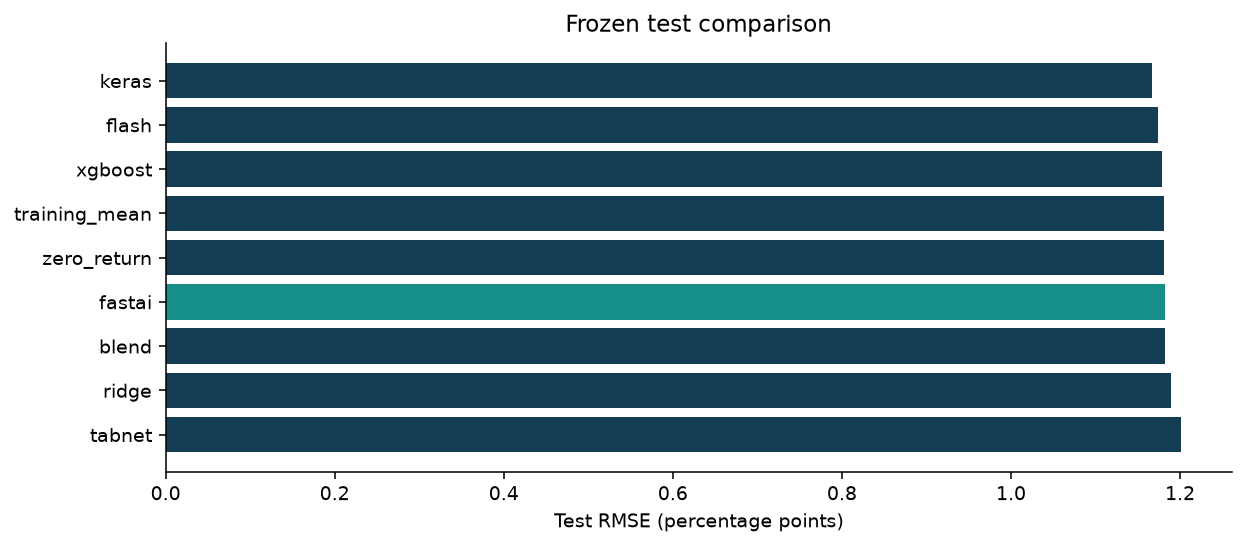

In [7]:
validation_scores = scores[scores.split == 'validation'].sort_values('RMSE').reset_index(drop=True)
test_scores = scores[scores.split == 'test'].sort_values('RMSE').reset_index(drop=True)
display(Markdown('### Development validation'))
display(validation_scores)
display(Markdown('### Frozen test period'))
display(test_scores)
# Independent NumPy recomputation of all published metrics from row predictions.
for split, p in predictions.items():
    y = p.target_return.to_numpy(dtype=float)
    for name in validation_scores.model:
        prediction = p[name].to_numpy(dtype=float)
        error = prediction-y
        independent = {
            'RMSE': np.sqrt(np.mean(error**2)), 'MAE': np.mean(np.abs(error)),
            'R2': 1-np.sum(error**2)/np.sum((y-y.mean())**2),
            'direction_accuracy': np.mean((y>0)==(prediction>0)), 'bias': np.mean(error),
        }
        saved = scores[(scores.split == split) & (scores.model == name)].iloc[0]
        assert int(saved.n) == len(y)
        for metric, value in independent.items():
            np.testing.assert_allclose(saved[metric], value, rtol=2e-6, atol=2e-8)
display(Markdown('All 18 saved model/split rows agree with independent row-level metric calculations within float32 rounding.'))
display(Image(filename=str(ROOT / 'results/figures/04_model_comparison.png'), width=950))


## 7. Blend selection and the frozen recommendation

The convex blend is `w × XGBoost + (1 − w) × deep_component`. The deep component
and the weight are chosen using development validation only. The 0.0–1.0 grid
includes both component endpoints. A blend need not outperform a baseline.
The final recommendation is the minimum-validation-RMSE model across all nine
candidates. The lowest test-RMSE model is descriptive and does not replace that
selection rule.


In [8]:
blend = read_json('results/blend_selection.json')
display(pd.DataFrame(blend['grid']))
display(pd.Series({
    'deep_component': blend['deep_component'],
    'xgboost_weight': blend['xgboost_weight'],
    'selection_data': blend['selection_data'],
    'validation_selected_model': summary['selected_model'],
    'selection_rule': summary['selection_rule'],
    'lowest_test_RMSE_descriptive_only': summary['best_test_model_descriptive_only'],
}).to_frame('Saved decision'))
selected = summary['selected_model']
selected_val = validation_scores.set_index('model').loc[selected]
assert selected_val.RMSE <= validation_scores.RMSE.min() + 1e-10
w = blend['xgboost_weight']
for p in predictions.values():
    np.testing.assert_allclose(p['blend'], w*p['xgboost']+(1-w)*p[blend['deep_component']], rtol=1e-6, atol=1e-8)
display(Markdown(f'The frozen validation-selected recommendation is **{selected}**. Saved blend predictions reconstruct from the recorded components and weight.'))
if w == 0:
    display(Markdown(f'The optional blend is 100% **{blend["deep_component"]}** here. It adds no gain, so the single-model explanation is sufficient.'))


,xgboost_weight,RMSE
0,0.000000,1.109562
1,0.100000,1.109742
2,0.200000,1.110149
3,0.300000,1.110781
4,0.400000,1.111639
5,0.500000,1.112722
6,0.600000,1.114029
7,0.700000,1.115560
8,0.800000,1.117313
9,0.900000,1.119288


,Saved decision
deep_component,fastai
xgboost_weight,0.000000
selection_data,validation only; no test optimization
validation_selected_model,fastai
selection_rule,lowest validation RMSE including baselines
lowest_test_RMSE_descriptive_only,keras


The frozen validation-selected recommendation is **fastai**. Saved blend predictions reconstruct from the recorded components and weight.

The optional blend is 100% **fastai** here. It adds no gain, so the single-model explanation is sufficient.

## 8. Native XGBoost TreeSHAP explanations

The ranking below reports mean absolute TreeSHAP contributions across the
development validation sample in model-output percentage points. Additivity is
checked using the same boosting iteration range as prediction. These explain
the fitted XGBoost model, even if a different model is the final recommendation.
Correlated features share predictive information; attribution is not causation.


,feature,mean_abs_shap
0,return_1,0.006426
1,return_lag_5,0.001570
2,return_lag_1,0.001358
3,drawdown_60,0.000996
4,rsi_14,0.000332
5,momentum_20,0.000273
6,return_lag_2,0.000000
7,momentum_10,0.000000
8,momentum_5,0.000000
9,return_lag_3,0.000000


,Native TreeSHAP check
max_additivity_error,0.000000
explained_partition,validation
method,XGBoost native TreeSHAP pred_contribs=True
bias_mean,0.047053


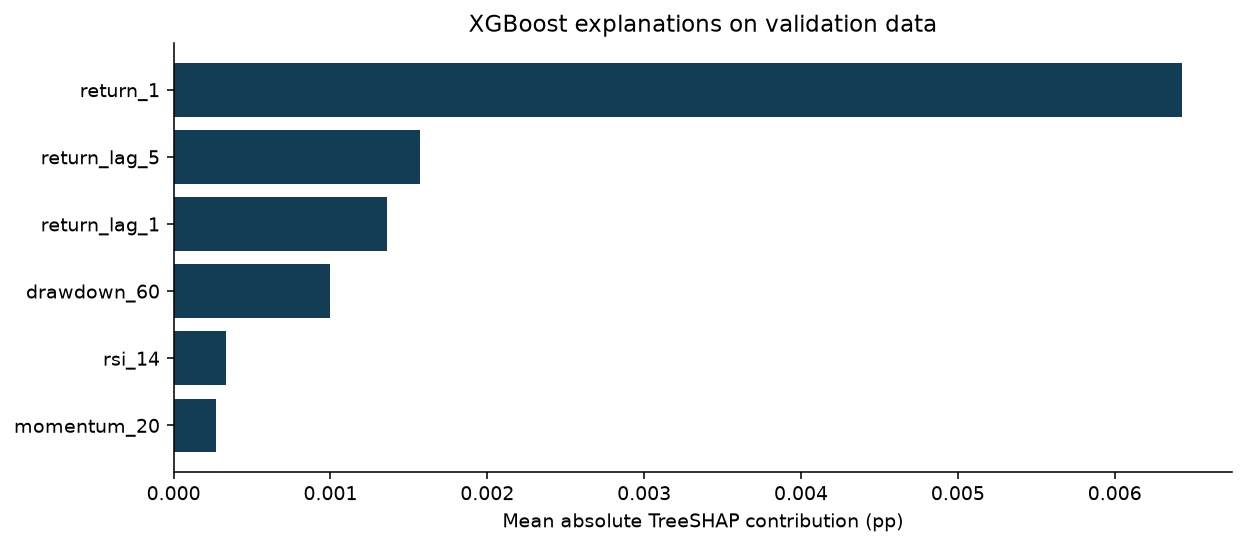

In [9]:
shap_path = ROOT / 'results/xgboost_shap_importance.csv'
if shap_path.exists():
    shap_importance = pd.read_csv(shap_path)
    display(shap_importance)
    shap_check = read_json('results/shap_check.json')
    display(pd.Series(shap_check).to_frame('Native TreeSHAP check'))
    assert float(shap_check['max_additivity_error']) < 1e-4
    figure = ROOT / 'results/figures/06_explanations.png'
    if figure.exists():
        display(Image(filename=str(figure), width=950))
else:
    display(Markdown('Native TreeSHAP was unavailable in this run. The recorded error is shown rather than an invented explanation.'))
    display(read_json('results/shap_error.json'))


## 9. Residuals and stability across test years

The diagnostic plot concerns the model selected by validation. Annual scores
are descriptive slices of the same frozen test period. They are not separate
model-selection exercises. A narrow set of near-zero predictions can still
obtain a reasonable RMSE on noisy returns, so inspect the baselines, scatter,
residual distribution and signed R-squared together.


,Observed minus predicted return (pp)
count,709.000000
mean,-0.040306
std,1.182243
min,-11.180489
25%,-0.622728
50%,0.031314
75%,0.615460
max,5.269346


,year,RMSE,MAE,R2,direction_accuracy,bias,n
0,2024,1.353974,0.877981,0.001899,0.546185,0.076460,249
1,2025,1.036322,0.770273,-0.016825,0.538153,-0.013016,249
2,2026,1.124538,0.853506,0.002534,0.568720,0.060566,211


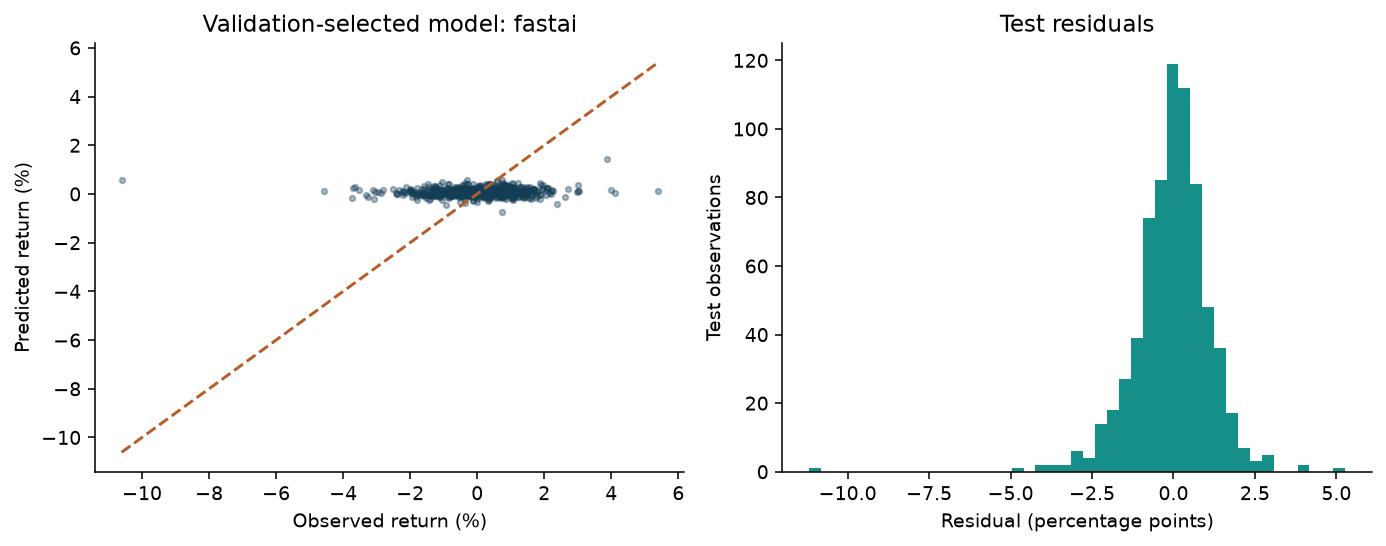

In [10]:
test_predictions = predictions['test']
residual = test_predictions.target_return - test_predictions[selected]
display(residual.describe().to_frame('Observed minus predicted return (pp)'))
annual = pd.read_csv(ROOT / 'results/annual_test_metrics.csv')
display(annual)
display(Image(filename=str(ROOT / 'results/figures/05_diagnostics.png'), width=1000))


## 10. Conclusion from the saved experiment

The paragraph below is generated from the actual saved selection and test
measurements. The test-best model is not retroactively declared the selected
model. A weak or negative forecasting result remains a valid project finding.


In [11]:
selected_test = test_scores.set_index('model').loc[selected]
zero_test = test_scores.set_index('model').loc['zero_return']
delta = float(zero_test.RMSE-selected_test.RMSE)
comparison = ('lower' if delta > 0 else 'higher' if delta < 0 else 'equal')
display(Markdown(
    f"Validation selected **{selected}**. On **{int(selected_test.n):,}** held-out observations, "
    f"its RMSE was **{selected_test.RMSE:.6f} pp**, MAE **{selected_test.MAE:.6f} pp**, "
    f"R² **{selected_test.R2:.6f}**, and directional accuracy **{selected_test.direction_accuracy:.2%}**. "
    f"Its RMSE was {comparison} than the zero-return baseline by **{abs(delta):.6f} pp**. "
    f"The lowest test RMSE belonged to **{summary['best_test_model_descriptive_only']}**, "
    f"which is a descriptive comparison rather than a new model-selection decision."
))
display(Markdown('### Practical interpretation'))
display(Markdown(
    'Simplicity concerns setup, code and runtime; transparency concerns how predictions can be explained; '
    'efficacy concerns the actual errors and stability. These dimensions should be discussed separately. '
    'The experiment covers one index, one feature design and one seed. Main development validation is used for '
    'stopping and blend selection. No executable trading profits or investment performance are established. '
    'Useful next experiments include rolling retraining, more time folds, multiple seeds and external features '
    'whose historical availability is known.'
))
display(pd.Series(summary['limits'], name='Recorded experiment limitations').to_frame())


Validation selected **fastai**. On **709** held-out observations, its RMSE was **1.182097 pp**, MAE **0.832870 pp**, R² **-0.002461**, and directional accuracy **55.01%**. Its RMSE was higher than the zero-return baseline by **0.000801 pp**. The lowest test RMSE belonged to **keras**, which is a descriptive comparison rather than a new model-selection decision.

### Practical interpretation

Simplicity concerns setup, code and runtime; transparency concerns how predictions can be explained; efficacy concerns the actual errors and stability. These dimensions should be discussed separately. The experiment covers one index, one feature design and one seed. Main development validation is used for stopping and blend selection. No executable trading profits or investment performance are established. Useful next experiments include rolling retraining, more time folds, multiple seeds and external features whose historical availability is known.

,Recorded experiment limitations
0,One index and one held-out era. Daily returns are noisy.
1,"Validation supports early stopping and blend selection, so validation scores are optimistic."
2,No investment performance or executable trading profits are claimed.
3,"Data are a price index, excluding dividend reinvestment."


## Reproduce or extend

This notebook's executed cells only inspect saved data and results. To rerun
the full experiment, activate the project environment and run the following
from the project root in a terminal:

```powershell
.\.venv\Scripts\python.exe src\pipeline.py
```

That command trains models and cross-validation folds and can take several
minutes. It was deliberately not launched by this notebook. Rebuild the
executed analysis afterward with:

```powershell
.\.venv\Scripts\python.exe scripts\build_notebook.py
```

Run checks with `python -m unittest discover -s tests -v`. See the README for
environment setup, the report for interpretation and the two course mapping
files under `references` for the unit-by-unit links. `.\run_demo.ps1` runs a
saved historical forecast. `.\run_all.ps1` retrains and rebuilds all deliverables,
including the report, presentation and ZIP. Each training run fits models again.
